In [1]:

import pandas as pd
import numpy as np
import joblib





final_model = joblib.load("salespulse_final_model.pkl")

print("Final model loaded successfully!")

Final model loaded successfully!


In [2]:
features = joblib.load("salespulse_features.pkl")

print("Features:")
print(features)

Features:
['year', 'month', 'day', 'day_of_week', 'week_of_year', 'is_event_day', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']


In [3]:
sales = pd.read_csv("../data/raw/sales_train_evaluation.csv")

calendar = pd.read_csv("../data/raw/calendar.csv")

calendar["date"] = pd.to_datetime(calendar["date"])

In [4]:
sales_cols = [col for col in sales.columns 
              if col.startswith("d_")]

print("Sales columns:")
print(sales_cols)

Sales columns:
['d_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112', 'd_113', 'd_114', 'd_115', 'd_116', 'd_117', 'd_118', 'd_119', 'd_120', 'd_121', 'd_

In [6]:
daily_totals = sales[sales_cols].sum(axis=0)

daily_sales = pd.DataFrame({
    "d": daily_totals.index,
    "total_sales": daily_totals.values
})

daily_totals

d_1       32631
d_2       31749
d_3       23783
d_4       25412
d_5       19146
          ...  
d_1937    37096
d_1938    36963
d_1939    42552
d_1940    51518
d_1941    54338
Length: 1941, dtype: int64

In [7]:
daily_sales = daily_sales.merge(
    calendar,
    on="d",
    how="left"
)

In [8]:
print(daily_sales[
    ["d", "date", "total_sales"]
].head())

print(daily_sales[
    ["d", "date", "total_sales"]
].tail())

     d       date  total_sales
0  d_1 2011-01-29        32631
1  d_2 2011-01-30        31749
2  d_3 2011-01-31        23783
3  d_4 2011-02-01        25412
4  d_5 2011-02-02        19146
           d       date  total_sales
1936  d_1937 2016-05-18        37096
1937  d_1938 2016-05-19        36963
1938  d_1939 2016-05-20        42552
1939  d_1940 2016-05-21        51518
1940  d_1941 2016-05-22        54338


In [9]:
daily_sales = daily_sales.sort_values("date").reset_index(drop=True)

daily_sales["lag_1"] = daily_sales["total_sales"].shift(1)
daily_sales["lag_7"] = daily_sales["total_sales"].shift(7)
daily_sales["lag_14"] = daily_sales["total_sales"].shift(14)
daily_sales["lag_28"] = daily_sales["total_sales"].shift(28)

daily_sales["rolling_mean_7"] = (
    daily_sales["total_sales"]
    .shift(1)
    .rolling(7)
    .mean()
)

daily_sales["rolling_mean_28"] = (
    daily_sales["total_sales"]
    .shift(1)
    .rolling(28)
    .mean()
)

In [10]:
daily_sales["year"] = daily_sales["date"].dt.year
daily_sales["month"] = daily_sales["date"].dt.month
daily_sales["day"] = daily_sales["date"].dt.day
daily_sales["day_of_week"] = daily_sales["date"].dt.dayofweek
daily_sales["week_of_year"] = (
    daily_sales["date"].dt.isocalendar().week.astype(int)
)

In [11]:

daily_sales["is_event_day"] = (
    daily_sales["event_name_1"].notna() |
    daily_sales["event_name_2"].notna()
).astype(int)


In [12]:
print(
    daily_sales[
        [
            "date",
            "total_sales",
            "lag_1",
            "lag_7",
            "lag_14",
            "lag_28",
            "rolling_mean_7",
            "rolling_mean_28",
            "year",
            "month",
            "day",
            "day_of_week",
            "week_of_year",
            "is_event_day"
        ]
    ].tail()
)

           date  total_sales    lag_1    lag_7   lag_14   lag_28  \
1936 2016-05-18        37096  38777.0  42248.0  39601.0  35343.0   
1937 2016-05-19        36963  37096.0  40503.0  40763.0  35033.0   
1938 2016-05-20        42552  36963.0  44073.0  43805.0  40517.0   
1939 2016-05-21        51518  42552.0  54308.0  54239.0  48962.0   
1940 2016-05-22        54338  51518.0  59921.0  45609.0  49795.0   

      rolling_mean_7  rolling_mean_28  year  month  day  day_of_week  \
1936    46027.428571     43533.821429  2016      5   18            2   
1937    45291.428571     43596.428571  2016      5   19            3   
1938    44785.714286     43665.357143  2016      5   20            4   
1939    44568.428571     43738.035714  2016      5   21            5   
1940    44169.857143     43829.321429  2016      5   22            6   

      week_of_year  is_event_day  
1936            20             0  
1937            20             0  
1938            20             0  
1939            20

In [13]:
prediction_data = daily_sales.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
).copy()

In [14]:
prediction_data 

,d,total_sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,...,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,day,day_of_week,week_of_year,is_event_day
28,d_29,29908,2011-02-26,11105,Saturday,1,2,2011,NaN,NaN,...,22529.0,31689.0,34833.0,32631.0,24143.142857,26238.678571,26,5,8,0
29,d_30,28707,2011-02-27,11105,Sunday,2,2,2011,NaN,NaN,...,29908.0,29283.0,36380.0,31749.0,23888.714286,26141.428571,27,6,8,0
30,d_31,21240,2011-02-28,11105,Monday,3,2,2011,NaN,NaN,...,28707.0,23966.0,21804.0,23783.0,23806.428571,26032.785714,28,0,9,0
31,d_32,22872,2011-03-01,11105,Tuesday,4,3,2011,NaN,NaN,...,21240.0,20501.0,24070.0,25412.0,23417.000000,25941.964286,1,1,9,0
32,d_33,22046,2011-03-02,11105,Wednesday,5,3,2011,NaN,NaN,...,22872.0,20757.0,21443.0,19146.0,23755.714286,25851.250000,2,2,9,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1936,d_1937,37096,2016-05-18,11616,Wednesday,5,5,2016,NaN,NaN,...,38777.0,42248.0,39601.0,35343.0,46027.428571,43533.821429,18,2,20,0
1937,d_1938,36963,2016-05-19,11616,Thursday,6,5,2016,NaN,NaN,...,37096.0,40503.0,40763.0,35033.0,45291.428571,43596.428571,19,3,20,0
1938,d_1939,42552,2016-05-20,11616,Friday,7,5,2016,NaN,NaN,...,36963.0,44073.0,43805.0,40517.0,44785.714286,43665.357143,20,4,20,0
1939,d_1940,51518,2016-05-21,11617,Saturday,1,5,2016,NaN,NaN,...,42552.0,54308.0,54239.0,48962.0,44568.428571,43738.035714,21,5,20,0


In [15]:
features

['year',
 'month',
 'day',
 'day_of_week',
 'week_of_year',
 'is_event_day',
 'lag_1',
 'lag_7',
 'lag_14',
 'lag_28',
 'rolling_mean_7',
 'rolling_mean_28']

In [16]:
X_prediction = prediction_data[features]

In [17]:
print("Prediction shape:", X_prediction.shape)
print("Number of features:", X_prediction.shape[1])
print(X_prediction.head())

Prediction shape: (1913, 12)
Number of features: 12
    year  month  day  day_of_week  week_of_year  is_event_day    lag_1  \
28  2011      2   26            5             8             0  22529.0   
29  2011      2   27            6             8             0  29908.0   
30  2011      2   28            0             9             0  28707.0   
31  2011      3    1            1             9             0  21240.0   
32  2011      3    2            2             9             0  22872.0   

      lag_7   lag_14   lag_28  rolling_mean_7  rolling_mean_28  
28  31689.0  34833.0  32631.0    24143.142857     26238.678571  
29  29283.0  36380.0  31749.0    23888.714286     26141.428571  
30  23966.0  21804.0  23783.0    23806.428571     26032.785714  
31  20501.0  24070.0  25412.0    23417.000000     25941.964286  
32  20757.0  21443.0  19146.0    23755.714286     25851.250000  


In [18]:
prediction_data["predicted_sales"] = final_model.predict(
    X_prediction
)

In [19]:
print(
    prediction_data[
        ["date", "total_sales", "predicted_sales"]
    ].tail(10)
)

           date  total_sales  predicted_sales
1931 2016-05-13        44073     43669.502220
1932 2016-05-14        54308     50319.997950
1933 2016-05-15        59921     51309.973935
1934 2016-05-16        42362     43716.049758
1935 2016-05-17        38777     39549.512123
1936 2016-05-18        37096     38716.867243
1937 2016-05-19        36963     38479.140817
1938 2016-05-20        42552     41752.841806
1939 2016-05-21        51518     49659.631939
1940 2016-05-22        54338     51749.117121


In [21]:
def predict_sales(date):
    date =pd.to_datetime(date)
    row = daily_sales[daily_sales["date"] == date]
    if row.empty:
        return "Date not found in the dataset."
    x=row[features]
    
    prediction = final_model.predict(x)[0]
    return prediction

In [23]:
predicted = predict_sales("2017-04-20")

print("Predicted sales:", predicted)

Predicted sales: Date not found in the dataset.


In [25]:
future_predictions = forecast_future_sales(
    "2016-04-25",
    7
)

print(future_predictions)

        date  predicted_sales
0 2016-04-25     41155.097293
1 2016-04-26     36462.420954
2 2016-04-27     35812.713433
3 2016-04-28     35816.091656
4 2016-04-29     40430.172425
5 2016-04-30     47547.764060
6 2016-05-01     57165.963529


In [27]:
print(calendar["date"].min())
print(calendar["date"].max())

2011-01-29 00:00:00
2016-06-19 00:00:00


In [28]:
print(
    calendar[
        ["date", "event_name_1", "event_type_1",
         "event_name_2", "event_type_2"]
    ].tail(30)
)

           date    event_name_1 event_type_1  event_name_2 event_type_2
1939 2016-05-21             NaN          NaN           NaN          NaN
1940 2016-05-22             NaN          NaN           NaN          NaN
1941 2016-05-23             NaN          NaN           NaN          NaN
1942 2016-05-24             NaN          NaN           NaN          NaN
1943 2016-05-25             NaN          NaN           NaN          NaN
1944 2016-05-26             NaN          NaN           NaN          NaN
1945 2016-05-27             NaN          NaN           NaN          NaN
1946 2016-05-28             NaN          NaN           NaN          NaN
1947 2016-05-29             NaN          NaN           NaN          NaN
1948 2016-05-30     MemorialDay     National           NaN          NaN
1949 2016-05-31             NaN          NaN           NaN          NaN
1950 2016-06-01             NaN          NaN           NaN          NaN
1951 2016-06-02  NBAFinalsStart     Sporting           NaN      

In [29]:
calendar["is_event_day"] = (
    calendar["event_name_1"].notna() |
    calendar["event_name_2"].notna()
).astype(int)

In [30]:
print(
    calendar[
        ["date", "event_name_1", "event_name_2", "is_event_day"]
    ].tail(30)
)

           date    event_name_1  event_name_2  is_event_day
1939 2016-05-21             NaN           NaN             0
1940 2016-05-22             NaN           NaN             0
1941 2016-05-23             NaN           NaN             0
1942 2016-05-24             NaN           NaN             0
1943 2016-05-25             NaN           NaN             0
1944 2016-05-26             NaN           NaN             0
1945 2016-05-27             NaN           NaN             0
1946 2016-05-28             NaN           NaN             0
1947 2016-05-29             NaN           NaN             0
1948 2016-05-30     MemorialDay           NaN             1
1949 2016-05-31             NaN           NaN             0
1950 2016-06-01             NaN           NaN             0
1951 2016-06-02  NBAFinalsStart           NaN             1
1952 2016-06-03             NaN           NaN             0
1953 2016-06-04             NaN           NaN             0
1954 2016-06-05             NaN         

In [31]:
def forecast_future_sales(start_date, days):

    history = daily_sales[
        ["date", "total_sales"]
    ].copy()

    history = history.sort_values("date").reset_index(drop=True)

    start_date = pd.to_datetime(start_date)

    future_dates = pd.date_range(
        start=start_date,
        periods=days,
        freq="D"
    )

    predictions = []

    for future_date in future_dates:

        # --------------------------------
        # 1. Get calendar information
        # --------------------------------

        calendar_row = calendar[
            calendar["date"] == future_date
        ]

        if calendar_row.empty:
            raise ValueError(
                f"No calendar information available for {future_date.date()}"
            )

        is_event_day = int(
            calendar_row["is_event_day"].iloc[0]
        )

        # --------------------------------
        # 2. Create calendar features
        # --------------------------------

        year = future_date.year
        month = future_date.month
        day = future_date.day
        day_of_week = future_date.dayofweek
        week_of_year = int(
            future_date.isocalendar().week
        )

        # --------------------------------
        # 3. Create lag features
        # --------------------------------

        lag_1 = history["total_sales"].iloc[-1]
        lag_7 = history["total_sales"].iloc[-7]
        lag_14 = history["total_sales"].iloc[-14]
        lag_28 = history["total_sales"].iloc[-28]

        # --------------------------------
        # 4. Create rolling features
        # --------------------------------

        rolling_mean_7 = (
            history["total_sales"]
            .iloc[-7:]
            .mean()
        )

        rolling_mean_28 = (
            history["total_sales"]
            .iloc[-28:]
            .mean()
        )

        # --------------------------------
        # 5. Create model input
        # --------------------------------

        input_row = pd.DataFrame([{
            "year": year,
            "month": month,
            "day": day,
            "day_of_week": day_of_week,
            "week_of_year": week_of_year,
            "is_event_day": is_event_day,
            "lag_1": lag_1,
            "lag_7": lag_7,
            "lag_14": lag_14,
            "lag_28": lag_28,
            "rolling_mean_7": rolling_mean_7,
            "rolling_mean_28": rolling_mean_28
        }])

        # Exact feature order
        input_row = input_row[features]

        # --------------------------------
        # 6. Predict
        # --------------------------------

        prediction = final_model.predict(
            input_row
        )[0]

        # Avoid negative sales
        prediction = max(0, prediction)

        # --------------------------------
        # 7. Store prediction
        # --------------------------------

        predictions.append({
            "date": future_date,
            "predicted_sales": prediction,
            "is_event_day": is_event_day
        })

        # --------------------------------
        # 8. Add prediction to history
        # --------------------------------

        history.loc[len(history)] = [
            future_date,
            prediction
        ]

    return pd.DataFrame(predictions)

In [32]:
future_predictions = forecast_future_sales(
    "2016-04-25",
    28
)

print(future_predictions)

         date  predicted_sales  is_event_day
0  2016-04-25     41155.097293             0
1  2016-04-26     36462.420954             0
2  2016-04-27     35812.713433             0
3  2016-04-28     35816.091656             0
4  2016-04-29     40430.172425             0
5  2016-04-30     45455.979215             1
6  2016-05-01     54755.050064             1
7  2016-05-02     46011.393671             0
8  2016-05-03     43424.616142             0
9  2016-05-04     41541.802664             0
10 2016-05-05     39727.554534             1
11 2016-05-06     44758.911742             0
12 2016-05-07     51442.266245             0
13 2016-05-08     51204.161479             1
14 2016-05-09     45804.452391             0
15 2016-05-10     41929.736143             0
16 2016-05-11     41854.228396             0
17 2016-05-12     41205.076089             0
18 2016-05-13     44458.778249             0
19 2016-05-14     50656.232776             0
20 2016-05-15     54895.938271             0
21 2016-05

In [33]:
actual_future = daily_sales[
    daily_sales["date"].isin(
        future_predictions["date"]
    )
][
    ["date", "total_sales"]
].copy()

actual_future = actual_future.rename(
    columns={
        "total_sales": "actual_sales"
    }
)

print(actual_future)

           date  actual_sales
1913 2016-04-25         38793
1914 2016-04-26         35487
1915 2016-04-27         34445
1916 2016-04-28         34732
1917 2016-04-29         42896
1918 2016-04-30         50429
1919 2016-05-01         53032
1920 2016-05-02         43181
1921 2016-05-03         44314
1922 2016-05-04         39601
1923 2016-05-05         40763
1924 2016-05-06         43805
1925 2016-05-07         54239
1926 2016-05-08         45609
1927 2016-05-09         46400
1928 2016-05-10         39379
1929 2016-05-11         42248
1930 2016-05-12         40503
1931 2016-05-13         44073
1932 2016-05-14         54308
1933 2016-05-15         59921
1934 2016-05-16         42362
1935 2016-05-17         38777
1936 2016-05-18         37096
1937 2016-05-19         36963
1938 2016-05-20         42552
1939 2016-05-21         51518
1940 2016-05-22         54338


In [34]:
forecast_comparison = future_predictions.merge(
    actual_future,
    on="date",
    how="left"
)

print(forecast_comparison)

         date  predicted_sales  is_event_day  actual_sales
0  2016-04-25     41155.097293             0         38793
1  2016-04-26     36462.420954             0         35487
2  2016-04-27     35812.713433             0         34445
3  2016-04-28     35816.091656             0         34732
4  2016-04-29     40430.172425             0         42896
5  2016-04-30     45455.979215             1         50429
6  2016-05-01     54755.050064             1         53032
7  2016-05-02     46011.393671             0         43181
8  2016-05-03     43424.616142             0         44314
9  2016-05-04     41541.802664             0         39601
10 2016-05-05     39727.554534             1         40763
11 2016-05-06     44758.911742             0         43805
12 2016-05-07     51442.266245             0         54239
13 2016-05-08     51204.161479             1         45609
14 2016-05-09     45804.452391             0         46400
15 2016-05-10     41929.736143             0         393

In [36]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib







forecast_mae = mean_absolute_error(
    forecast_comparison["actual_sales"],
    forecast_comparison["predicted_sales"]
)

forecast_rmse = np.sqrt(
    mean_squared_error(
        forecast_comparison["actual_sales"],
        forecast_comparison["predicted_sales"]
    )
)

forecast_r2 = r2_score(
    forecast_comparison["actual_sales"],
    forecast_comparison["predicted_sales"]
)

print("28-Day Forecast MAE:", forecast_mae)
print("28-Day Forecast RMSE:", forecast_rmse)
print("28-Day Forecast R²:", forecast_r2)

28-Day Forecast MAE: 2108.7308070162762
28-Day Forecast RMSE: 2518.973746332542
28-Day Forecast R²: 0.8559954777689094


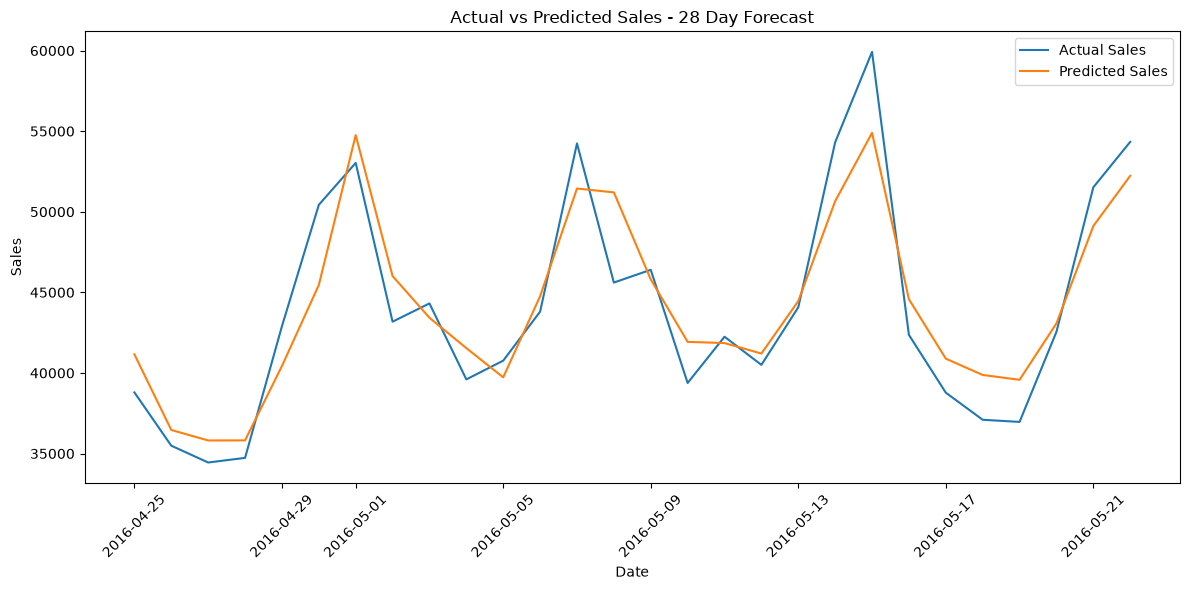

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_comparison["date"],
    forecast_comparison["actual_sales"],
    label="Actual Sales"
)

plt.plot(
    forecast_comparison["date"],
    forecast_comparison["predicted_sales"],
    label="Predicted Sales"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Actual vs Predicted Sales - 28 Day Forecast")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [38]:
import joblib

joblib.dump(
    final_model,
    "salespulse_final_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [39]:
joblib.dump(
    features,
    "salespulse_features.pkl"
)

print("Features saved successfully!")


Features saved successfully!


In [40]:
loaded_model = joblib.load(
    "salespulse_final_model.pkl"
)

loaded_features = joblib.load(
    "salespulse_features.pkl"
)

print("Model loaded:", type(loaded_model))
print("Features loaded:", loaded_features)

Model loaded: <class 'sklearn.linear_model._base.LinearRegression'>
Features loaded: ['year', 'month', 'day', 'day_of_week', 'week_of_year', 'is_event_day', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']
